# 03 · Temas → libros

Recomendación top-10 para 53 287 lectores (partición temporal por lector) y el experimento de **libros
nuevos**: 1 000 libros retirados de las calificaciones y del modelo de texto; se evalúan los 960 con
sinopsis, recomendados solo con sus temas predichos.

In [1]:
import json
import sys

import pandas as pd
from book_topics import MODULE

from common import data_dir, setup_style

setup_style()
d = data_dir(MODULE)
P = d.parent
report = json.loads((P / "resultados" / "metrics.json").read_text())
b = report["parte_b"]
print(
    "colaborativo elegido en validación:",
    b["colaborativo_elegido"],
    "| α del híbrido:",
    b["alpha_hibrido"],
)
tab = pd.DataFrame(b["modelos"]).T
tab.round(4)

colaborativo elegido en validación: PureSVD (k=100) | α del híbrido: 0.75


,ndcg@10,cobertura,percentil_popularidad
popularidad,0.0377,0.0057,99.9234
colaborativo,0.0539,0.1546,96.5494
temas,0.0134,0.6167,72.6775
hibrido,0.0548,0.1601,96.5102


**Lectura.** El colaborativo (PureSVD) mejora a la popularidad en NDCG@10 (0,054 frente a 0,038) y
el híbrido apenas lo supera (0,055). El recomendador **solo por temas** queda muy abajo en NDCG (0,013)
pero tiene la mayor cobertura del catálogo (62 % frente a 15 %) y recomienda libros mucho menos
populares (percentil 73 frente a 97). Es un recomendador de *descubrimiento*, no de acierto.

El desempate por popularidad (peso < 1e-9) del puntaje de temas se agregó *después* de ver test: en
la primera ejecución (`metrics_v1_sin_desempate.json`, con la partición por lector anterior) temas pasó
de 0,010 a 0,018. Es un ajuste post hoc, y H2 depende de él porque el híbrido usa ese puntaje (ver
README).

## 1. Por cuartil de historial (H2)

H2 híbrido − colaborativo (Q1): Δ = +0.0008 IC [+0.0005, +0.0012] p_Holm = 0.0015


,popularidad,colaborativo,temas,hibrido
Q1,0.0300,0.0485,0.0107,0.0494
Q2,0.0329,0.0513,0.0118,0.0520
Q3,0.0403,0.0561,0.0140,0.0571
Q4,0.0470,0.0591,0.0167,0.0601


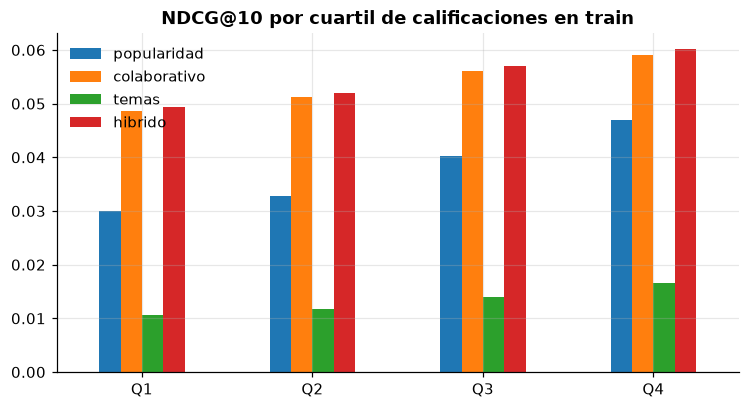

In [2]:
hist = pd.DataFrame(b["por_historial"]).T
hist.plot.bar(figsize=(8, 4), rot=0, title="NDCG@10 por cuartil de calificaciones en train")
h2 = report["hipotesis"]["H2"]
lo, hi = h2["ci"]
print(
    f"H2 híbrido − colaborativo (Q1): Δ = {h2['diff']:+.4f} IC [{lo:+.4f}, {hi:+.4f}]",
    f"p_Holm = {h2['p_holm']:.4f}",
)
hist.round(4)

**Lectura.** H2 es estadísticamente significativa (Δ = +0,0008, p_Holm = 0,0015) pero **irrelevante
en la práctica**: menos de un milésimo de NDCG. Con 13 000 lectores por cuartil, el bootstrap detecta diferencias
minúsculas. Lo que sí muestra la tabla es que todos los modelos mejoran con más historial, y que la
ventaja del colaborativo sobre la popularidad es mayor en Q1 (+0,019) que en Q4 (+0,012).

## 2. Libros nuevos (H3)

In [3]:
new = report["libros_nuevos"]
h3 = report["hipotesis"]["H3"]
print(new)
lo, hi = h3["ci"]
print(
    f"H3 temas − popularidad: Δ = {h3['diff']:+.4f} IC [{lo:+.4f}, {hi:+.4f}]",
    f"p_Holm = {h3['p_holm']:.4f} → apoya: {h3['apoya_hipotesis']}",
)

{'n_libros_nuevos': 960, 'n_usuarios': 52377, 'ndcg@10': {'temas_predichos': 0.042745063109365176, 'popularidad (optimista)': 0.1429983722429537, 'aleatorio': 0.00901538245066519}}
H3 temas − popularidad: Δ = -0.1003 IC [-0.1019, -0.0985] p_Holm = 0.0015 → apoya: False


**Lectura.** H3 **no se apoya**: para 960 libros que el sistema nunca vio en calificaciones, recomendar
por temas predichos (0,043) es 4,7 veces mejor que al azar (0,009) pero queda muy debajo de la
popularidad (0,143). Ojo: esa popularidad es *optimista*, porque usa las calificaciones de los libros
nuevos, que en un arranque en frío real no existirían. Aun contra esa referencia inalcanzable, los temas
son la única señal disponible el día 1 y claramente aportan sobre el azar.

## 3. La CLI con lectores inventados

In [4]:
import subprocess

for args in (
    ["recomendar", "--lei", "Dune", "Foundation", "The Hobbit"],
    ["recomendar", "--lei", "Pride and Prejudice", "Jane Eyre", "--no-me-gusto", "Twilight"],
):
    out = subprocess.run(
        [sys.executable, "-m", "book_topics", *args], capture_output=True, text=True
    ).stdout
    print("$", " ".join(args), "\n" + out)

$ recomendar --lei Dune Foundation The Hobbit 
«Dune» → Dune (Dune Chronicles #1) (también: Dune Messiah (Dune Chronicles #2); Dune Road)
«Foundation» → Foundation (Foundation #1) (también: Foundation and Empire (Foundation #2); Foundation's Edge (Foundation #4); Foundation and Earth (Foundation #5))
«The Hobbit» → The Hobbit (también: The Hobbit: Graphic Novel)
1. Dune Messiah (Dune Chronicles #2) — porque te gustan: Clásicos, Fantasía, Ciencia ficción
2. The Great Dune Trilogy   — porque te gustan: Clásicos, Fantasía, Ciencia ficción
3. The Fellowship of the Ring (The Lord of the Rings, #1) — porque te gustan: Clásicos, Fantasía
4. The Two Towers (The Lord of the Rings, #2) — porque te gustan: Clásicos, Fantasía
5. The Return of the King (The Lord of the Rings, #3) — porque te gustan: Clásicos, Fantasía
6. The Lord of the Rings (The Lord of the Rings, #1-3) — porque te gustan: Clásicos, Fantasía
7. The Time Machine — porque te gustan: Clásicos, Ciencia ficción
8. Stranger in a Strang

$ recomendar --lei Pride and Prejudice Jane Eyre --no-me-gusto Twilight 
«Pride and Prejudice» → Pride and Prejudice (también: Pride and Prejudice and Zombies (Pride and Prejudice and Zombies, #1))
«Twilight» → Twilight (Twilight, #1) (también: Twilight: The Complete Illustrated Movie Companion; Twilight Director's Notebook : The Story of How We Made the Movie Based on the Novel by Stephenie Meyer; Twilight: The Graphic Novel, Vol. 1 (Twilight: The Graphic Novel, #1))
1. Mansfield Park — porque te gustan: Romance, Literatura, Clásicos
2. The Complete Novels — porque te gustan: Romance, Literatura, Clásicos
3. Emma — porque te gustan: Romance, Literatura, Clásicos
4. Anna Karenina — porque te gustan: Romance, Literatura, Clásicos
5. Love in the Time of Cholera — porque te gustan: Romance, Literatura, Clásicos
6. Persuasion — porque te gustan: Romance, Literatura, Clásicos
7. Northanger Abbey — porque te gustan: Romance, Literatura, Clásicos
8. A Room with a View — porque te gustan: Roma